# Part 2. Temporal K-means (variant 3)
Single subject, single run (HCP language task, story vs math).

Run the cells in order, with the `neural_signal` kernel, from the repository folder.

Inputs (run `Project_notebook.ipynb` and `02_glm.ipynb` first):
- part 1-2: `func_mc_brain_smooth6mm.nii.gz` (313 volumes) and the functional brain mask;
- part 1-3: the design matrices (`design_matrix_block.csv`, `design_matrix_event.csv`), the story - math
  z-map and the Yeo atlas.

- **1** Temporal K-means, one timepoint = one sample
- **2** Choice of the number of clusters, centroid maps
- **3** Binary time courses of the clusters vs the GLM regressors

In [1]:
import os
import os.path as op

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.patches import Patch
from nilearn import plotting, signal
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

# Paths relative to the notebook folder: works on every machine without editing
root_dir = op.abspath(".")
data_dir = op.join(root_dir, "data")
out_dir = op.join(data_dir, "derivatives")
func_dir = op.join(out_dir, "func")
glm_dir = op.join(out_dir, "glm")
km_dir = op.join(out_dir, "kmeans")
fig_dir = op.join(out_dir, "figures")
for d in (km_dir, fig_dir):
    os.makedirs(d, exist_ok=True)
FIG_DPI = 300

FWHM = 6                                            # mm, smoothing chosen in part 1-2
func_img_path = op.join(func_dir, f"func_mc_brain_smooth{FWHM}mm.nii.gz")
func_mask = op.join(func_dir, "func_mean_brain_mask.nii.gz")
events_path = op.join(func_dir, "task_onsets_used.csv")
anat_mni = op.join(out_dir, "anat", "T1w_brain_MNI_SyN.nii.gz")              # part 1-1
dm_block_path = op.join(glm_dir, "design_matrix_block.csv")                   # part 1-3
dm_event_path = op.join(glm_dir, "design_matrix_event.csv")
zmap_path = op.join(glm_dir, "zmap_story_minus_math.nii.gz")
yeo_path = op.join(out_dir, "atlases", "Yeo2011_7Networks_N1000.split_components.FSL_MNI152_2mm.nii.gz")
yeo_lut_path = op.join(out_dir, "atlases", "7Networks_ColorLUT_freeview.txt")

for path in (func_img_path, func_mask, events_path, anat_mni, dm_block_path, dm_event_path, zmap_path, yeo_path):
    assert op.exists(path), f"{path} not found: run Project_notebook.ipynb and 02_glm.ipynb first"

## 1. Temporal K-means

**Samples and features.** As in lab 7, each timepoint (fMRI volume) is one sample and each brain voxel is one
feature: X has 313 rows (timepoints) and ~234 000 columns (voxels of the functional mask of part 1-2). The
clustering groups timepoints whose whole-brain activity pattern is similar, so each cluster is a recurring brain
"state", and its centroid (the mean pattern of its timepoints) is a spatial map.

**Data.** The preprocessed run of part 1-2 (first 3 volumes removed, motion-corrected, smoothed 6 mm).

**Normalisation.** Lab 7 removes the mean of each voxel over time, so that the clustering sees the fluctuations
and not the anatomy (the mean EPI intensity). We also divide each voxel by its standard deviation (z-score):
the raw BOLD variance differs a lot between voxels (vessels, brain edges, CSF have a much larger variance than
grey matter), and with the Euclidean distance these few voxels would dominate the clustering. After the
z-score every voxel has the same weight, and the centroids are in units of standard deviation.

We do not regress out the drifts and the motion before clustering: this is tested in section 2 ("preprocessing
check"), and it makes the clustering less stable without making it more related to the task. Their influence is
checked afterwards in point 3, by correlating the clusters with the drift and motion regressors.

**Computation.** K-means with the Euclidean distance (`sklearn.cluster.KMeans`, as in lab 7). Since there are
only 313 samples, they span a space of at most 313 dimensions: we run K-means on the SVD coordinates of X
(313 x 313), which keep exactly all the distances between timepoints, so the clustering is identical to the one
on the 234 000 voxels but ~1000 times faster. The centroids are then computed back in voxel space.

In [2]:
mask_img = nib.load(func_mask)
mask = mask_img.get_fdata() > 0
func_img = nib.load(func_img_path)
t_r = float(func_img.header.get_zooms()[3])
X_raw = func_img.get_fdata(dtype=np.float32)[mask].T                 # timepoints x voxels
n_scans, n_voxels = X_raw.shape
print(f"X: {n_scans} timepoints x {n_voxels} voxels, TR = {t_r:.2f} s")

X = signal.clean(X_raw, detrend=False, standardize="zscore_sample")  # demean (lab 7) + unit variance per voxel

# Exact low-dimensional coordinates of the timepoints (same pairwise distances as in voxel space)
U, S, _ = np.linalg.svd(X, full_matrices=False)
X_red = U * S                                                         # timepoints x 313
assert np.allclose(np.linalg.norm(X_red[0] - X_red[1]), np.linalg.norm(X[0] - X[1]), rtol=1e-3)

X: 313 timepoints x 234273 voxels, TR = 0.72 s


## 2. Number of clusters

Three criteria, for K = 2 ... 20:
- **inertia** (within-cluster sum of squares, the elbow criterion of lab 7);
- **silhouette** (how much closer each timepoint is to its own cluster than to the next one, from -1 to 1);
- **stability**: K-means depends on its random initialisation; we rerun it with 10 different seeds and measure
  the agreement with the reference solution (adjusted Rand index, 1 = identical partition, 0 = chance).

In [3]:
K_RANGE = range(2, 21)
N_SEEDS = 10
N_INIT = 20

rows = []
for k in K_RANGE:
    ref = KMeans(n_clusters=k, random_state=0, n_init=N_INIT).fit(X_red)
    ari = [adjusted_rand_score(ref.labels_, KMeans(n_clusters=k, random_state=s, n_init=N_INIT).fit(X_red).labels_)
           for s in range(1, N_SEEDS + 1)]
    rows.append({"K": k, "inertia": ref.inertia_, "silhouette": silhouette_score(X_red, ref.labels_),
                 "stability (ARI)": np.mean(ari), "stability sd": np.std(ari)})
k_table = pd.DataFrame(rows)
k_table.to_csv(op.join(km_dir, "choice_of_K.csv"), index=False)
print(k_table.round(3).to_string(index=False))

 K    inertia  silhouette  stability (ARI)  stability sd
 2 66933096.0       0.078            0.989         0.017
 3 63820276.0       0.057            0.956         0.036
 4 61078072.0       0.066            0.956         0.033
 5 59286204.0       0.069            0.887         0.051
 6 58262004.0       0.059            0.668         0.058
 7 57126176.0       0.052            0.718         0.087
 8 56173788.0       0.055            0.703         0.055
 9 55228176.0       0.055            0.721         0.054
10 54905368.0       0.047            0.691         0.049
11 53888096.0       0.055            0.643         0.053
12 53853712.0       0.049            0.573         0.041
13 52916776.0       0.052            0.584         0.042
14 52572720.0       0.041            0.567         0.038
15 52210968.0       0.042            0.494         0.021
16 51816408.0       0.037            0.525         0.056
17 51121648.0       0.038            0.482         0.033
18 50827368.0       0.040      

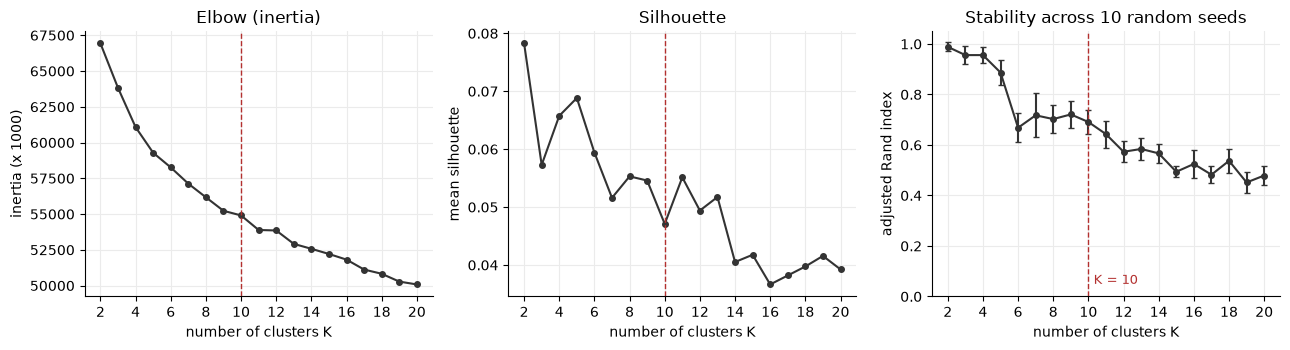

In [4]:
K = 10                                              # chosen number of clusters (see the comments below)

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
axs[0].plot(k_table["K"], k_table["inertia"] / 1e3, "o-", color="#333333", ms=4)
axs[0].set(xlabel="number of clusters K", ylabel="inertia (x 1000)", title="Elbow (inertia)")
axs[1].plot(k_table["K"], k_table["silhouette"], "o-", color="#333333", ms=4)
axs[1].set(xlabel="number of clusters K", ylabel="mean silhouette", title="Silhouette")
axs[2].errorbar(k_table["K"], k_table["stability (ARI)"], yerr=k_table["stability sd"], fmt="o-",
                color="#333333", ms=4, capsize=2)
axs[2].set(xlabel="number of clusters K", ylabel="adjusted Rand index", ylim=(0, 1.05),
           title=f"Stability across {N_SEEDS} random seeds")
for ax in axs:
    ax.axvline(K, color="#b3302f", ls="--", lw=1)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color="0.92")
    ax.set_xticks(range(2, 21, 2))
axs[2].text(K + 0.3, 0.05, f"K = {K}", color="#b3302f", fontsize=9)
fig.tight_layout()
fig.savefig(op.join(fig_dir, "8a_choice_of_K.png"), dpi=FIG_DPI)
plt.show()

### Preprocessing check: removing the drifts and the motion before clustering?

At K = 10, the clustering is repeated on the data cleaned in four ways (each voxel is always z-scored):
1. nothing removed (the version used);
2. 0.01 Hz high-pass filter (same cut-off as the GLM);
3. the 4 cosine drift regressors of the GLM regressed out;
4. the drifts and the 6 motion parameters regressed out.

For each version: stability across 5 seeds (adjusted Rand index), fraction of consecutive timepoints in the same
cluster (temporal contiguity), largest |correlation| of a binary cluster time course with `story` and `math`,
number of clusters with |r| > 0.3 with one of them, and mean (over clusters) of the largest |r| with a drift.

In [5]:
dm_block = pd.read_csv(dm_block_path, index_col=0)
drifts = dm_block[[c for c in dm_block.columns if c.startswith("drift")]].to_numpy()
motion = dm_block[["rot_x", "rot_y", "rot_z", "trans_x", "trans_y", "trans_z"]].to_numpy()
cleaning = {"nothing removed (used)": {},
            "high-pass 0.01 Hz": {"t_r": t_r, "high_pass": 0.01},
            "cosine drifts": {"confounds": drifts},
            "cosine drifts + motion": {"confounds": np.column_stack([drifts, motion])}}

rows = []
for name, kwargs in cleaning.items():
    Y = signal.clean(X_raw, detrend=False, standardize="zscore_sample", **kwargs)
    U_y, S_y, _ = np.linalg.svd(Y, full_matrices=False)
    Y_red = U_y * S_y
    lab = KMeans(n_clusters=K, random_state=0, n_init=200).fit(Y_red).labels_
    ari = [adjusted_rand_score(lab, KMeans(n_clusters=K, random_state=s, n_init=N_INIT).fit(Y_red).labels_)
           for s in range(1, 6)]
    onehot = np.array([(lab == c).astype(float) for c in range(K)])
    r_task = np.array([[np.corrcoef(b, dm_block[t])[0, 1] for t in ("story", "math")] for b in onehot])
    r_drift = np.array([[abs(np.corrcoef(b, d)[0, 1]) for d in drifts.T] for b in onehot])
    rows.append({"cleaning": name, "stability (ARI)": np.mean(ari), "contiguity": np.mean(lab[1:] == lab[:-1]),
                 "max |r| story": np.abs(r_task[:, 0]).max(), "max |r| math": np.abs(r_task[:, 1]).max(),
                 "clusters |r task| > 0.3": int((np.abs(r_task).max(axis=1) > 0.3).sum()),
                 "mean max |r drift|": r_drift.max(axis=1).mean()})
    del Y, Y_red
cleaning_table = pd.DataFrame(rows)
cleaning_table.to_csv(op.join(km_dir, f"preprocessing_check_K{K}.csv"), index=False)
print(cleaning_table.round(2).to_string(index=False))
del X_raw

              cleaning  stability (ARI)  contiguity  max |r| story  max |r| math  clusters |r task| > 0.3  mean max |r drift|
nothing removed (used)             0.70        0.74           0.43          0.47                        3                0.34
     high-pass 0.01 Hz             0.42        0.70           0.45          0.48                        2                0.19
         cosine drifts             0.41        0.55           0.42          0.45                        2                0.16
cosine drifts + motion             0.26        0.51           0.30          0.29                        1                0.10


In [6]:
# Final clustering, with many initialisations to get the best solution
kmeans = KMeans(n_clusters=K, random_state=0, n_init=200).fit(X_red)

# Clusters ordered by size (number of timepoints), largest first: "the first 10 clusters" = all of them here
sizes = np.bincount(kmeans.labels_, minlength=K)
order = np.argsort(-sizes)
labels = np.argsort(order)[kmeans.labels_]                            # relabel: 0 = largest cluster
sizes = sizes[order]

# Centroids in voxel space: mean z-scored pattern of the timepoints of each cluster
centroids = np.stack([X[labels == c].mean(axis=0) for c in range(K)])  # K x voxels
centroid_data = np.zeros(mask.shape + (K,), dtype=np.float32)
centroid_data[mask] = centroids.T
centroid_img = nib.Nifti1Image(centroid_data, mask_img.affine)
centroid_img.to_filename(op.join(km_dir, f"centroids_K{K}.nii.gz"))
np.savetxt(op.join(km_dir, f"labels_K{K}.txt"), labels, fmt="%d")
print("Timepoints per cluster:", dict(enumerate(sizes)))

Timepoints per cluster: {0: np.int64(48), 1: np.int64(43), 2: np.int64(42), 3: np.int64(35), 4: np.int64(31), 5: np.int64(30), 6: np.int64(27), 7: np.int64(24), 8: np.int64(23), 9: np.int64(10)}


### Centroid maps

Each centroid is shown in axial view on the T1 registered to MNI (part 1-1), in units of standard deviation of
each voxel (z). Positive (red): the voxel is above its mean during the timepoints of the cluster; negative (blue):
below. Values with |z| < 0.3 are not coloured, to keep the maps readable.

To relate the maps to part 1, each title gives the spatial correlation of the centroid with the story - math
z-map of the GLM (3d), and the Yeo network with the highest mean centroid value.

In [7]:
from nilearn import image

z_glm = nib.load(zmap_path).get_fdata()[mask]
r_glm = np.array([np.corrcoef(centroids[c], z_glm)[0, 1] for c in range(K)])

# Yeo networks (same atlas and 4 mm dilation as in 02_glm.ipynb)
from scipy import ndimage

NETWORKS = {"Vis": "Visual", "SomMot": "Somatomotor", "DorsAttn": "Dorsal attention",
            "SalVentAttn": "Ventral attention", "Limbic": "Limbic", "Cont": "Frontoparietal",
            "Default": "Default mode"}
lut = pd.read_csv(yeo_lut_path, sep=r"\s+", header=None, usecols=[0, 1], names=["index", "name"])
lut = lut[lut["index"] > 0]
lut["network"] = lut["name"].str.split("_").str[2].map(NETWORKS)
yeo_split = np.squeeze(nib.load(yeo_path).get_fdata()).astype(int)
dist, (ii, jj, kk) = ndimage.distance_transform_edt(yeo_split == 0, return_indices=True)
yeo_split = np.where(mask & (dist <= 2), yeo_split[ii, jj, kk], yeo_split)
yeo_net = np.full(yeo_split.shape, "", dtype=object)
for _, row in lut.iterrows():
    yeo_net[yeo_split == row["index"]] = row["network"]
yeo_net = yeo_net[mask]

net_means = pd.DataFrame({net: centroids[:, yeo_net == net].mean(axis=1) for net in NETWORKS.values()},
                         index=[f"C{c + 1}" for c in range(K)])
net_means.to_csv(op.join(km_dir, f"centroid_network_means_K{K}.csv"))
summary = pd.DataFrame({"cluster": [f"C{c + 1}" for c in range(K)], "timepoints": sizes,
                        "% of run": np.round(100 * sizes / n_scans, 1),
                        "r with story-math map": r_glm.round(2),
                        "top network (+)": net_means.idxmax(axis=1).values,
                        "bottom network (-)": net_means.idxmin(axis=1).values})
summary.to_csv(op.join(km_dir, f"cluster_summary_K{K}.csv"), index=False)
print(summary.to_string(index=False))
print("\nMean centroid value per Yeo network (z):\n", net_means.round(2).to_string())

cluster  timepoints  % of run  r with story-math map  top network (+) bottom network (-)
     C1          48      15.3                   0.35           Limbic   Dorsal attention
     C2          43      13.7                   0.32     Default mode     Frontoparietal
     C3          42      13.4                  -0.71   Frontoparietal       Default mode
     C4          35      11.2                  -0.16   Frontoparietal        Somatomotor
     C5          31       9.9                   0.21           Visual             Limbic
     C6          30       9.6                  -0.05           Limbic   Dorsal attention
     C7          27       8.6                  -0.24 Dorsal attention             Limbic
     C8          24       7.7                  -0.24           Limbic             Visual
     C9          23       7.3                   0.27      Somatomotor  Ventral attention
    C10          10       3.2                  -0.01   Frontoparietal       Default mode

Mean centroid value 

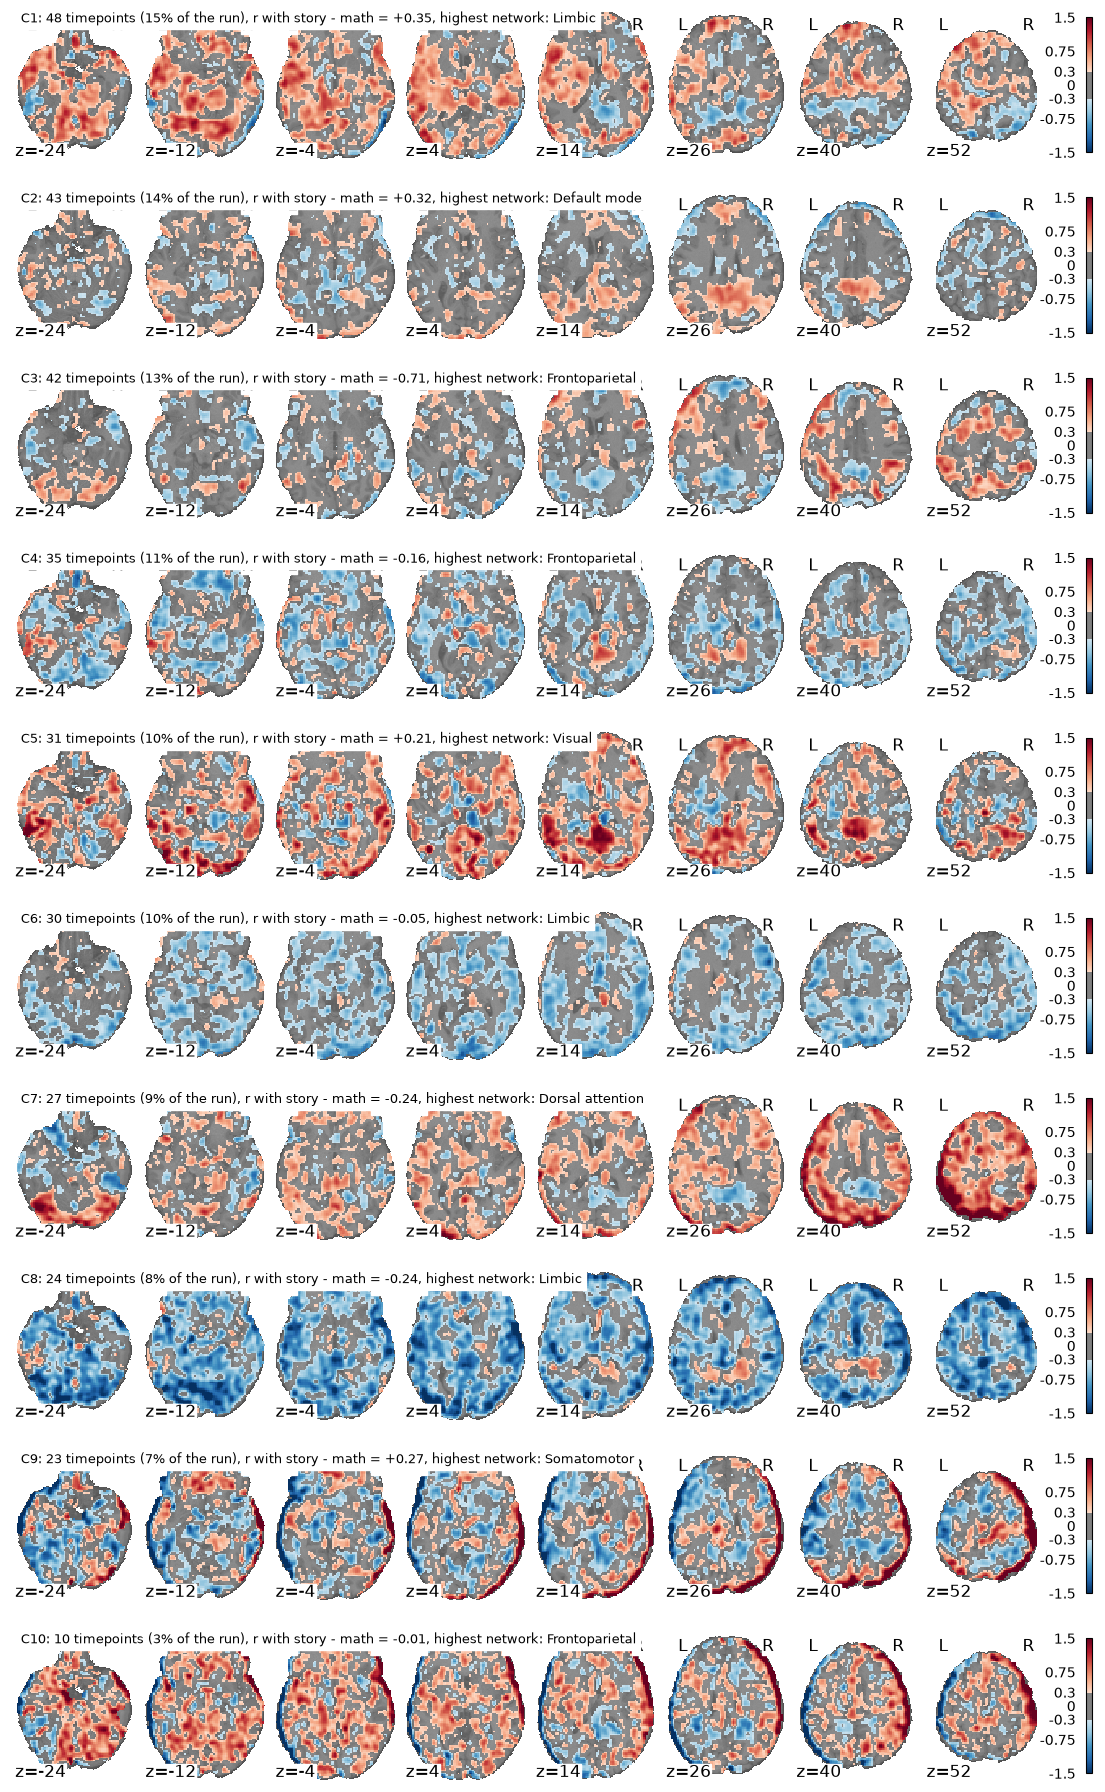

In [8]:
Z_CUTS = [-24, -12, -4, 4, 14, 26, 40, 52]          # same axial slices as the GLM maps
VMAX = 1.5
fig, axs = plt.subplots(K, 1, figsize=(14, 2.3 * K))
for c, ax in enumerate(axs):
    display = plotting.plot_stat_map(image.index_img(centroid_img, c), bg_img=anat_mni, display_mode="z",
                                     cut_coords=Z_CUTS, axes=ax, threshold=0.3, vmax=VMAX, cmap="RdBu_r",
                                     black_bg=False, draw_cross=False)
    display.title(f"C{c + 1}: {sizes[c]} timepoints ({100 * sizes[c] / n_scans:.0f}% of the run), "
                  f"r with story - math = {r_glm[c]:+.2f}, highest network: {summary['top network (+)'][c]}",
                  size=9, color="black", bgcolor="white")
fig.savefig(op.join(fig_dir, "8b_centroid_maps.png"), dpi=FIG_DPI, bbox_inches="tight")
plt.show()

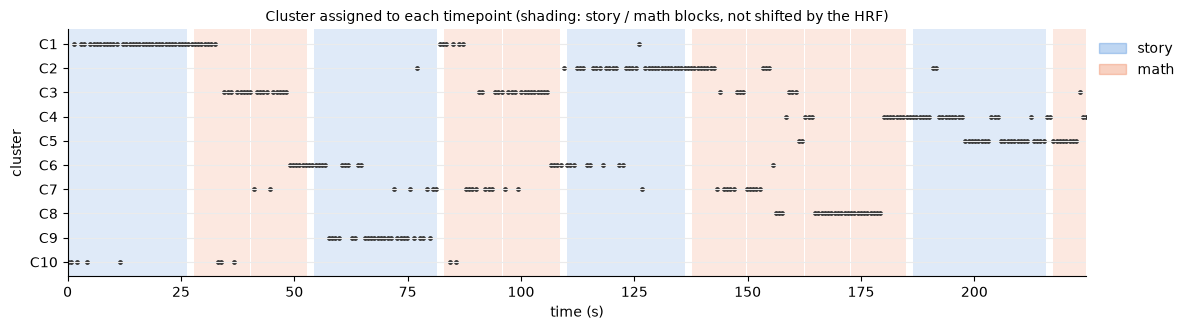

In [9]:
# Figure: cluster of each timepoint over the run, with the story and math blocks
STORY_COLOR, MATH_COLOR = "#2a78d6", "#eb6834"
events = pd.read_csv(events_path)
frame_times = np.arange(n_scans) * t_r

fig, ax = plt.subplots(figsize=(12, 3.4))
for _, ev in events[events["trial_type"].isin(["story", "math"])].iterrows():
    color = STORY_COLOR if ev["trial_type"] == "story" else MATH_COLOR
    ax.axvspan(ev["onset"], ev["onset"] + ev["duration"], color=color, alpha=0.15, lw=0)
ax.scatter(frame_times, labels + 1, c="#333333", s=6)
ax.set(xlabel="time (s)", ylabel="cluster", xlim=(0, frame_times[-1]), ylim=(K + 0.6, 0.4))
ax.set_yticks(range(1, K + 1), [f"C{c}" for c in range(1, K + 1)])
ax.set_title("Cluster assigned to each timepoint (shading: story / math blocks, not shifted by the HRF)", fontsize=10)
ax.legend(handles=[Patch(color=STORY_COLOR, alpha=0.3, label="story"), Patch(color=MATH_COLOR, alpha=0.3, label="math")],
          loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="0.92")
fig.tight_layout()
fig.savefig(op.join(fig_dir, "8c_cluster_time_course.png"), dpi=FIG_DPI)
plt.show()

## 3. Cluster time courses vs GLM regressors

For each of the first 10 clusters (here all K = 10, ordered by size), the binary time course is 1 at the
timepoints assigned to the cluster and 0 elsewhere. It is correlated (Pearson) with the regressors of the GLM of
part 1-3, all already convolved with the HRF:
- task, block design: `story`, `math`;
- task, event design: the 7 sub-events (`present_*`, `question_*`, `response_*`, `cue`);
- nuisance: the 6 motion parameters and the 4 cosine drifts, to detect clusters driven by motion or slow drifts
  rather than by the task (they were not regressed out before clustering).

With 313 timepoints, |r| > 0.11 is significant at p < 0.05 (uncorrected) if the samples were independent; fMRI
timepoints are autocorrelated, so the effective threshold is higher, and the correlations are interpreted by
their size rather than their p-value.

In [10]:
dm_block = pd.read_csv(dm_block_path, index_col=0)
dm_event = pd.read_csv(dm_event_path, index_col=0)
assert len(dm_block) == n_scans
EVENT_CONDITIONS = ["present_story", "question_story", "response_story",
                    "present_math", "question_math", "response_math", "cue"]
motion_cols = ["rot_x", "rot_y", "rot_z", "trans_x", "trans_y", "trans_z"]
drift_cols = [c for c in dm_block.columns if c.startswith("drift")]
regressors = pd.concat([dm_block[["story", "math"]], dm_event[EVENT_CONDITIONS],
                        dm_block[motion_cols + drift_cols]], axis=1)

N_FIRST = min(10, K)
binary = pd.DataFrame({f"C{c + 1}": (labels == c).astype(float) for c in range(N_FIRST)})
corr = pd.DataFrame([[np.corrcoef(binary[b], regressors[r])[0, 1] for r in regressors] for b in binary],
                    index=binary.columns, columns=regressors.columns)
corr.to_csv(op.join(km_dir, f"correlation_clusters_regressors_K{K}.csv"))
print(corr.round(2).to_string())

     story  math  present_story  question_story  response_story  present_math  question_math  response_math   cue  rot_x  rot_y  rot_z  trans_x  trans_y  trans_z  drift_1  drift_2  drift_3  drift_4
C1    0.33 -0.36           0.16            0.20            0.22         -0.25          -0.25          -0.25 -0.02  -0.35  -0.05   0.19     0.11     0.30    -0.17     0.52     0.37     0.29     0.25
C2    0.22 -0.23           0.13            0.14            0.10         -0.24          -0.16          -0.03  0.12   0.26   0.05   0.04     0.05    -0.37    -0.16    -0.14    -0.43     0.30     0.22
C3   -0.43  0.47          -0.30           -0.19           -0.15          0.48           0.24           0.17 -0.12  -0.19   0.03   0.10     0.14     0.20     0.04     0.17    -0.15    -0.08    -0.03
C4   -0.06  0.07          -0.02           -0.05           -0.09          0.02           0.10           0.04  0.06   0.13   0.23  -0.12     0.20     0.26    -0.15    -0.44     0.27    -0.06    -0.11
C5    0.26

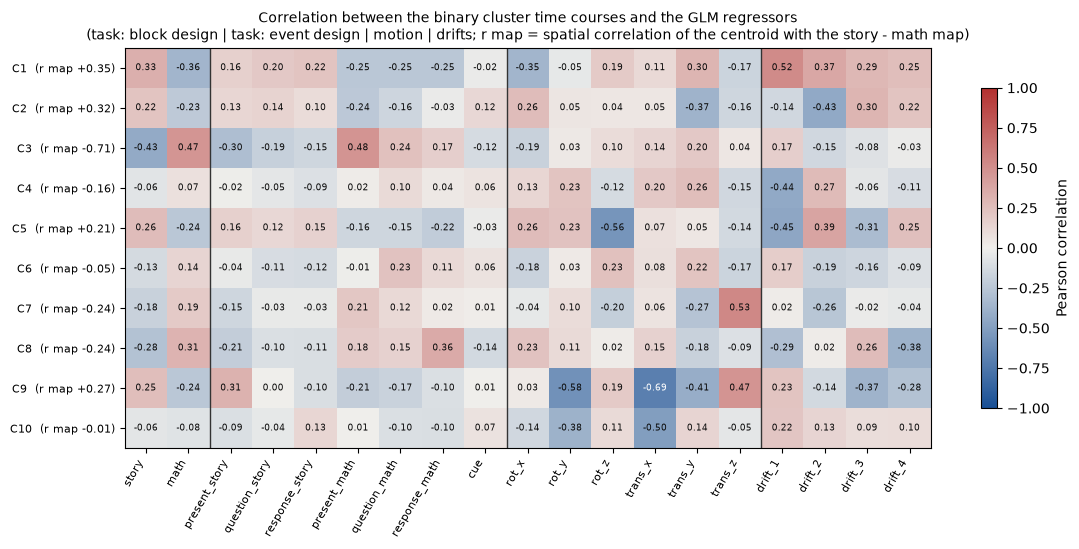

In [11]:
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#184f95", "#f0efec", "#b3302f"])
fig, ax = plt.subplots(figsize=(13, 5.2))
im = ax.imshow(corr.to_numpy(), cmap=DIVERGING, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(corr.shape[1]), corr.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(N_FIRST), [f"{c}  (r map {r:+.2f})" for c, r in zip(corr.index, r_glm)], fontsize=8)
for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        v = corr.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5, color="white" if abs(v) > 0.6 else "#0b0b0b")
for x in (1.5, 8.5, 14.5):                                             # block | event | motion | drift
    ax.axvline(x, color="#333333", lw=1)
ax.set_title("Correlation between the binary cluster time courses and the GLM regressors\n"
             "(task: block design | task: event design | motion | drifts; r map = spatial correlation of the "
             "centroid with the story - math map)", fontsize=10)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson correlation")
fig.savefig(op.join(fig_dir, "8d_correlation_clusters_regressors.png"), dpi=FIG_DPI, bbox_inches="tight")
plt.show()

### Comments on the choice of K (`8a_choice_of_K.png`)

- **Inertia**: it decreases smoothly with K, without a clear elbow.
- **Silhouette**: low for every K (0.04-0.08). fMRI timepoints do not form well separated groups: brain
  activity changes continuously, so any partition cuts through a continuum. The silhouette therefore cannot
  pick K on its own.
- **Stability**: the partition is almost identical across seeds for K ≤ 5 (adjusted Rand index 0.89-0.99),
  then stays on a plateau around 0.70 for K = 6-10, and decreases beyond (0.64 at K = 11, < 0.6 from K = 12).

We choose **K = 10**, the largest K before the stability drops: it gives the finest partition that is still
reproducible, and it provides the 10 clusters analysed in point 3. K ≤ 5 is more stable but too coarse: it
merges the task states with the slow fluctuations described below.

**Preprocessing check** (table above, `preprocessing_check_K10.csv`). Removing the slow drifts (0.01 Hz high-pass, or the 4 cosine drifts of the GLM) and
the motion before clustering was tested at K = 10: it does not make the clusters more related to the task (max
|r| with story 0.30-0.45 vs 0.43; fewer clusters with |r| > 0.3 with a task regressor) and it reduces the
stability (adjusted Rand index 0.26-0.42 vs 0.70). We therefore keep the z-scored data and check the nuisance
effects in point 3.

### Comments on the centroid maps and on point 3 (`8b`, `8c`, `8d`)

**Most clusters are consecutive segments of the run.** The time course (`8c`) shows that 9 of the 10 clusters
each cover one or two continuous periods of ~15-35 s. Consecutive volumes are similar because of slow
fluctuations (scanner drift, global signal, slow head motion), and with the Euclidean distance these
fluctuations are as large as the task effect. K-means is unsupervised: it groups the timepoints by whatever
varies most, task or not. Only one cluster comes back across the run.

**Task states.**
- **C3 = math state.** It is the only recurrent cluster: it comes back in the first three math blocks (~35-48,
  90-106 and 145-160 s, i.e. the blocks shifted by the hemodynamic delay). Its centroid is positive in the
  intraparietal sulcus and lateral prefrontal cortex (frontoparietal and dorsal attention networks) and
  negative in the posterior cingulate / precuneus (default mode). It is the mirror image of the GLM contrast:
  spatial correlation -0.71 with the story - math map, and its time course correlates with `math` (0.47) and
  `present_math` (0.48), the regressor of the listening/computing phase.
- **C1 and C2 = story states.** C1 covers the first story block (0-33 s), C2 the third one (110-143 s). Their
  centroids are positive in the default mode network (posterior cingulate / precuneus, medial prefrontal) and
  correlate positively with the story - math map (+0.35, +0.32); their time courses correlate with `story` (0.33,
  0.22). But each one covers essentially a single block, so they also follow the slow drifts (C1 with `drift_1`,
  0.52; C2 with `drift_2`, -0.43): a story block at the start and one in the middle of the run are not similar
  enough to fall in the same cluster.

**Nuisance states.**
- **C9 and C10 = motion.** Their centroids show strong values along the edge of the brain, with opposite signs
  on opposite edges: this is the signature of a small displacement of the head (the edge voxels move in or out of
  the brain). Their time courses correlate with the motion parameters (C9: `trans_x` -0.69, `rot_y` -0.58,
  `trans_z` 0.47; C10: `trans_x` -0.50), much more than with the task. C9 covers the second story block
  (57-80 s), so its moderate correlation with `story` (0.25) comes from timing, not from story processing.
- **C7 and C8 = global signal.** C8 is negative almost everywhere (mean centroid -0.35 to -0.74 in every Yeo
  network) during the four consecutive math blocks (~157-180 s); C7 is positive almost everywhere, mostly in
  the dorsal cortex, in short periods of the math blocks, and correlates with `trans_z` (0.53). Whole-brain
  increases or decreases of the signal are typical of breathing, arousal or motion, not of a specific network.
- **C4, C5, C6**: segments at the end of the run (C4 ~180-197 s, C5 ~197-225 s, last story block) and at the
  math-to-story transitions (C6), correlated with the drifts and motion (C4: `drift_1` -0.44; C5: `rot_z` -0.56,
  `drift_1` -0.45). C5 has a visual / default mode centroid (+0.21 with the story - math map).

**Relation with the GLM.** The K-means finds the main result of part 1 without knowing the task: the
frontoparietal "math" state (C3) and default-mode "story" states (C1, C2) are the two sides of the story - math
contrast (3d-3e). But they explain only part of the run, and the other clusters are dominated by drift, global
signal and motion. The GLM separates these sources because it models them explicitly (drift and motion
regressors) and tests the task with a predefined, HRF-convolved model; the K-means has no such model, and its
clusters must be interpreted afterwards by correlating them with the regressors, as done here.